# Causal activation patching: a practical first experiment

**This notebook demonstrates causal methodology on a factual example, not a discovery about sociolinguistic register.** GPT-2 may or may not satisfy the baseline behavioral check. Do not claim a causal result until inspecting the actual outputs.

In [1]:
%pip -q install "transformer-lens>=4,<5" matplotlib

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


## What the method does
- Compare two almost-identical prompts with different country names.
- Measure the model’s preference for the corresponding capital city.
- Replace **one internal activation** from one prompt with the activation from the other.
- Check whether this changes the model’s prediction.

An effective patch identifies a causally influential activation under the chosen intervention; it does **not**, alone, identify a complete neural circuit.

Loading GPT-2 small on cuda (first run downloads weights)...


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  548MB            

model.safetensors: downloading bytes:           |  0.00B            

...

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

Clean Paris-minus-Rome logit difference:     +1.405
Corrupted Paris-minus-Rome logit difference: -4.417
Behavioral separation:                     +5.822
Wrote results/patching_results.csv and results/patching_results.png
Exploratory example only; repeat on a preregistered set of prompt pairs.


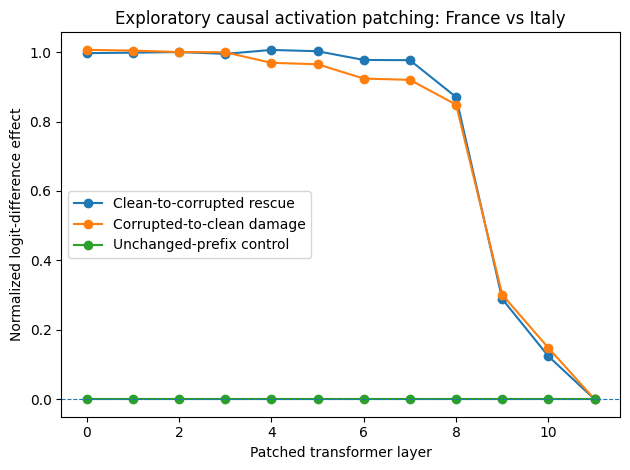

In [2]:
"""Exploratory activation patching with TransformerLens 4.x and GPT-2 small.

Model downloads are required when running. This script deliberately makes no
claims about an outcome until you have inspected the empirical results.
"""

import csv
from pathlib import Path

import matplotlib.pyplot as plt
import torch

CLEAN = "The capital of France is"
CORRUPTED = "The capital of Italy is"
TARGET_CLEAN = " Paris"
TARGET_CORRUPTED = " Rome"


def single_token_id(model, text):
    """Return one continuation token ID; reject multi-token answers."""
    tokens = model.to_tokens(text, prepend_bos=False)
    if tokens.shape != (1, 1):
        raise ValueError(f"Expected one token for {text!r}; got {tokens.shape}")
    return int(tokens[0, 0])


def changed_token_position(clean_tokens, corrupted_tokens):
    """Ensure the prompts differ at exactly one token position."""
    if clean_tokens.shape != corrupted_tokens.shape:
        raise ValueError("Clean and corrupted prompts have different token lengths")
    changed = torch.where(clean_tokens[0] != corrupted_tokens[0])[0].tolist()
    if len(changed) != 1:
        raise ValueError(f"Expected one changed position, found {changed}")
    return int(changed[0])


def logit_difference(logits, positive_id, negative_id):
    """Unnormalized preference for positive over negative continuation."""
    return float((logits[0, -1, positive_id] - logits[0, -1, negative_id]).item())


def normalized_recovery(patched_score, corrupted_score, clean_score):
    """0 = corrupted baseline; 1 = clean baseline; values can exceed [0,1]."""
    denominator = clean_score - corrupted_score
    if abs(denominator) < 1e-6:
        raise ValueError("Behavioral baseline difference is too small for normalization")
    return (patched_score - corrupted_score) / denominator


def patch_position(model, base_tokens, source_cache, layer, position):
    """Replace a single residual-stream activation at one layer and position."""
    name = f"blocks.{layer}.hook_resid_post"
    source = source_cache[name]

    def patch(activation, hook):
        modified = activation.clone()
        modified[:, position, :] = source[:, position, :]
        return modified

    return model.run_with_hooks(base_tokens, fwd_hooks=[(name, patch)])


def main():
    from transformer_lens.model_bridge import TransformerBridge

    torch.manual_seed(0)
    device = "cuda" if torch.cuda.is_available() else "cpu"
    print(f"Loading GPT-2 small on {device} (first run downloads weights)...")
    model = TransformerBridge.boot_transformers("gpt2", device=device)
    model.eval()

    clean_tokens = model.to_tokens(CLEAN)
    corrupted_tokens = model.to_tokens(CORRUPTED)
    changed_position = changed_token_position(
    clean_tokens, corrupted_tokens
)

patch_target_position = clean_tokens.shape[1] - 1
prefix_control_position = changed_position - 1
    if country_position == 0:
        raise ValueError("No unchanged prefix token available for a negative control")
    prefix_control_position = country_position - 1
    paris = single_token_id(model, TARGET_CLEAN)
    rome = single_token_id(model, TARGET_CORRUPTED)

    with torch.no_grad():
        names_filter = lambda name: name.endswith(".hook_resid_post")
        clean_logits, clean_cache = model.run_with_cache(clean_tokens, names_filter=names_filter)
        corrupted_logits, corrupted_cache = model.run_with_cache(
            corrupted_tokens, names_filter=names_filter
        )
        clean_score = logit_difference(clean_logits, paris, rome)
        corrupted_score = logit_difference(corrupted_logits, paris, rome)
        gap = clean_score - corrupted_score
        print(f"Clean Paris-minus-Rome logit difference:     {clean_score:+.3f}")
        print(f"Corrupted Paris-minus-Rome logit difference: {corrupted_score:+.3f}")
        print(f"Behavioral separation:                     {gap:+.3f}")
        if gap <= 0.5:
            raise RuntimeError(
                "Behavioral separation is too weak for this exploratory patching demo. "
                "Do not interpret or report a causal circuit. Check the chosen prompt pair."
            )

        rows = []
        for layer in range(model.cfg.n_layers):
            rescued_logits = patch_position(
                model, corrupted_tokens, clean_cache, layer, country_position
            )
            damaged_logits = patch_position(
                model, clean_tokens, corrupted_cache, layer, country_position
            )
            control_logits = patch_position(
                model, corrupted_tokens, clean_cache, layer, prefix_control_position
            )
            rescue_score = logit_difference(rescued_logits, paris, rome)
            damage_score = logit_difference(damaged_logits, paris, rome)
            control_score = logit_difference(control_logits, paris, rome)
            rows.append(
                {
                    "layer": layer,
                    "rescue_recovery": normalized_recovery(
                        rescue_score, corrupted_score, clean_score
                    ),
                    "reverse_damage": (clean_score - damage_score) / gap,
                    "unchanged_prefix_control": normalized_recovery(
                        control_score, corrupted_score, clean_score
                    ),
                }
            )

    result_dir = Path("results")
    result_dir.mkdir(exist_ok=True)
    with (result_dir / "patching_results.csv").open("w", newline="") as f:
        writer = csv.DictWriter(f, fieldnames=list(rows[0]))
        writer.writeheader()
        writer.writerows(rows)
    layers = [r["layer"] for r in rows]
    for field, label in [
        ("rescue_recovery", "Clean-to-corrupted rescue"),
        ("reverse_damage", "Corrupted-to-clean damage"),
        ("unchanged_prefix_control", "Unchanged-prefix control"),
    ]:
        plt.plot(layers, [r[field] for r in rows], marker="o", label=label)
    plt.axhline(0, linestyle="--", linewidth=0.8)
    plt.xlabel("Patched transformer layer")
    plt.ylabel("Normalized logit-difference effect")
    plt.title("Exploratory causal activation patching: France vs Italy")
    plt.legend()
    plt.tight_layout()
    plt.savefig(result_dir / "patching_results.png", dpi=170)
    print("Wrote results/patching_results.csv and results/patching_results.png")
    print("Exploratory example only; repeat on a preregistered set of prompt pairs.")


if __name__ == "__main__":
    main()


## Interpret the results
1. Did the baseline score change in the expected direction? If not, stop rather than interpret the patch.
2. Were clean→corrupted and corrupted→clean interventions directionally consistent?
3. Was the unchanged-prefix negative control close to zero?
4. Did the effect vary by layer?
5. Repeat with multiple preregistered pairs and confidence intervals before a causal research claim.

**Next experiment:** design semantically matched formal/informal prompts, preregister a behavioral gate, then investigate internal activations only after the model passes it.

,layer,rescue_recovery,reverse_damage,unchanged_prefix_control
0,0,0.997040,1.006675,0.0
1,1,0.998449,1.004386,0.0
2,2,1.000238,1.000249,0.0
3,3,0.994937,0.999485,0.0
4,4,1.006308,0.969206,0.0
5,5,1.002559,0.965017,0.0
6,6,0.977472,0.923761,0.0
7,7,0.976759,0.920174,0.0
8,8,0.870559,0.848726,0.0
9,9,0.288686,0.301032,0.0


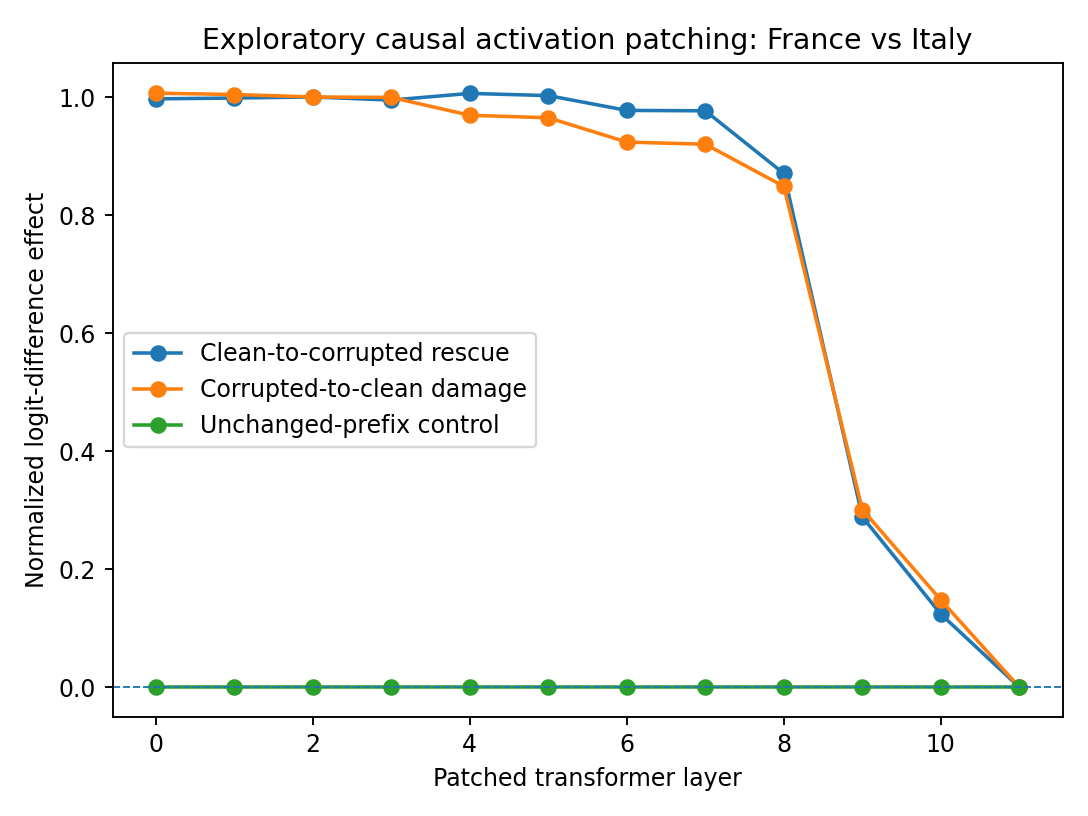

In [3]:
import pandas as pd
from IPython.display import display, Image

# Display the results table
results = pd.read_csv("results/patching_results.csv")
display(results)

# Display the activation-patching graph
display(Image(filename="results/patching_results.png"))


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

Clean score: 1.405
Corrupted score: -4.417
Behavioral separation: 5.822


,layer,rescue_recovery,reverse_damage,unchanged_prefix_control
0,0,-0.006675,0.002960,0.0
1,1,-0.004386,0.001551,0.0
2,2,-0.000249,-0.000238,0.0
3,3,0.000515,0.005063,0.0
4,4,0.030794,-0.006308,0.0
5,5,0.034983,-0.002559,0.0
6,6,0.076239,0.022528,0.0
7,7,0.079826,0.023241,0.0
8,8,0.151274,0.129441,0.0
9,9,0.698968,0.711314,0.0


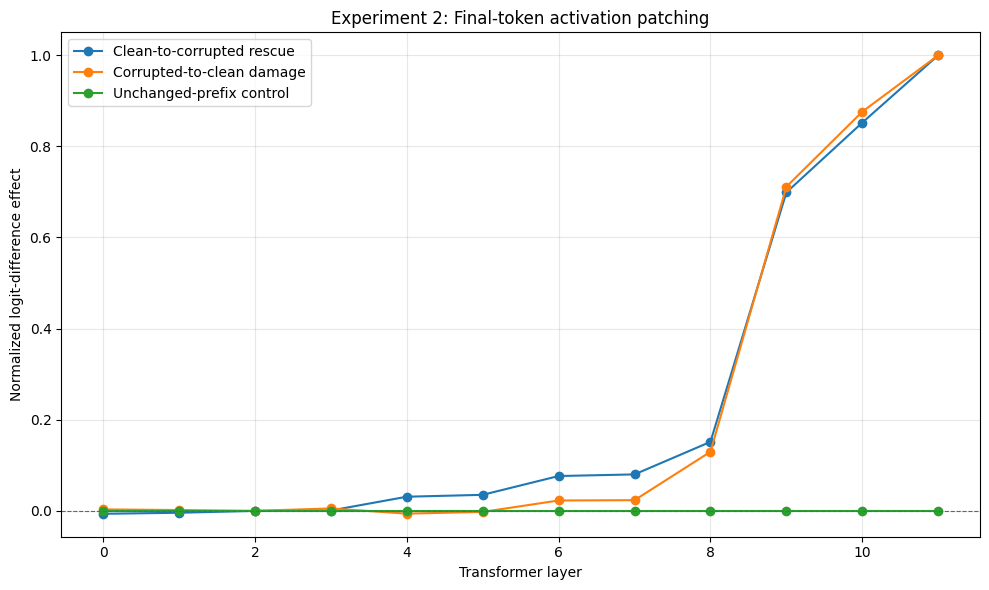

Experiment 2 completed!
Results saved in: results_final_position


In [4]:
# EXPERIMENT 2: PATCH THE FINAL TOKEN
# Keep your original experiment unchanged.

import torch
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from transformer_lens.model_bridge import TransformerBridge

torch.manual_seed(0)

device = "cuda" if torch.cuda.is_available() else "cpu"
model = TransformerBridge.boot_transformers("gpt2", device=device)
model.eval()

clean_tokens = model.to_tokens("The capital of France is")
corrupted_tokens = model.to_tokens("The capital of Italy is")

paris = single_token_id(model, " Paris")
rome = single_token_id(model, " Rome")

# NEW: Patch the LAST token rather than the country token
final_position = clean_tokens.shape[1] - 1
country_position = changed_token_position(
    clean_tokens, corrupted_tokens
)

if country_position == 0:
    raise ValueError("No unchanged prefix token available")

prefix_position = country_position - 1

with torch.no_grad():

    names_filter = lambda name: name.endswith(".hook_resid_post")

    clean_logits, clean_cache = model.run_with_cache(
        clean_tokens, names_filter=names_filter
    )
    corrupted_logits, corrupted_cache = model.run_with_cache(
        corrupted_tokens, names_filter=names_filter
    )

    clean_score = logit_difference(clean_logits, paris, rome)
    corrupted_score = logit_difference(corrupted_logits, paris, rome)
    gap = clean_score - corrupted_score

    print("Clean score:", round(clean_score, 3))
    print("Corrupted score:", round(corrupted_score, 3))
    print("Behavioral separation:", round(gap, 3))

    if gap <= 0.5:
        raise ValueError("Behavioral separation too small")

    results = []

    for layer in range(model.cfg.n_layers):

        rescued = patch_position(
            model, corrupted_tokens, clean_cache,
            layer, final_position
        )

        damaged = patch_position(
            model, clean_tokens, corrupted_cache,
            layer, final_position
        )

        control = patch_position(
            model, corrupted_tokens, clean_cache,
            layer, prefix_position
        )

        rescue_score = logit_difference(rescued, paris, rome)
        damage_score = logit_difference(damaged, paris, rome)
        control_score = logit_difference(control, paris, rome)

        results.append({
            "layer": layer,
            "rescue_recovery": normalized_recovery(
                rescue_score, corrupted_score, clean_score
            ),
            "reverse_damage": (clean_score - damage_score) / gap,
            "unchanged_prefix_control": normalized_recovery(
                control_score, corrupted_score, clean_score
            )
        })

# Show results
df = pd.DataFrame(results)
display(df)

# Save separately from Experiment 1
folder = Path("results_final_position")
folder.mkdir(exist_ok=True)

df.to_csv(folder / "patching_results.csv", index=False)

# Generate graph
plt.figure(figsize=(10, 6))

plt.plot(
    df["layer"], df["rescue_recovery"],
    marker="o", label="Clean-to-corrupted rescue"
)

plt.plot(
    df["layer"], df["reverse_damage"],
    marker="o", label="Corrupted-to-clean damage"
)

plt.plot(
    df["layer"], df["unchanged_prefix_control"],
    marker="o", label="Unchanged-prefix control"
)

plt.axhline(0, linestyle="--", linewidth=0.8)
plt.xlabel("Transformer layer")
plt.ylabel("Normalized logit-difference effect")
plt.title("Experiment 2: Final-token activation patching")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(folder / "patching_results.png", dpi=170)
plt.show()

print("Experiment 2 completed!")
print("Results saved in:", folder)

In [5]:

import shutil

shutil.make_archive(
    "/content/activation_patching_results",
    "zip",
    "/content",
    "results"
)

shutil.make_archive(
    "/content/final_position_results",
    "zip",
    "/content",
    "results_final_position"
)

from google.colab import files

files.download("/content/activation_patching_results.zip")
files.download("/content/final_position_results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>